# Ablation Comparison (within_subject_day)

对比 4 组实验的 `within_subject_day` 结果（mean±sd，5 seeds）：
- **CNN-Full** — `result_day_td/tsize8`
- **CNN-Ablation** — `result_day_td_ablation/tsize8`
- **MLP-Full** — `results_mlp`
- **MLP-Ablation** — `results_mlp_ablation`

In [1]:
import os, re, glob
import numpy as np
import pandas as pd

EXPERIMENTS = {
    'CNN-Full':     '/root/zjm/cadt/result_day_td/tsize8',
    'CNN-Ablation': '/root/zjm/cadt/result_day_td_ablation/tsize8',
    'MLP-Full':     '/root/zjm/cadt/results_mlp',
    'MLP-Ablation': '/root/zjm/cadt/results_mlp_ablation',
}
SPLIT_MODE = 'within_subject_day'

OVERALL_METRICS = [
    ('Test MSE',              'Test MSE'),
    ('Test MAE',              'Test MAE'),
    ('Test RMSE',             'Test RMSE'),
    ('Test R2',               'Test R2'),
    ('Test Avg R2 (per-dim)', 'Test Avg R2'),
    ('Test Pearson',          'Test Pearson'),
    ('Test Spearman',         'Test Spearman'),
    ('Val MSE',               'Val MSE'),
    ('Val MAE',               'Val MAE'),
    ('Val RMSE',              'Val RMSE'),
    ('Val R2',                'Val R2'),
    ('Val Avg R2 (per-dim)',  'Val Avg R2'),
    ('Val Pearson',           'Val Pearson'),
    ('Val Spearman',          'Val Spearman'),
]

EMOTIONS = [
    'inspired', 'alert', 'determined', 'attentive', 'active',
    'hostile', 'nervous', 'upset', 'afraid', 'ashamed', 'fatigue'
]
PER_EMOTION_METRICS = ['MSE', 'MAE', 'R2', 'Pearson', 'Spearman']

print('Config loaded.')

Config loaded.


## 解析函数

In [2]:
def parse_results_txt(filepath):
    with open(filepath, 'r') as f:
        text = f.read()

    overall = {}
    for key in [m[0] for m in OVERALL_METRICS]:
        pattern = re.escape(key) + r":\s*([-+]?\d*\.?\d+)"
        m = re.search(pattern, text)
        if m:
            overall[key] = float(m.group(1))

    per_emotion_test, per_emotion_val = {}, {}

    test_section = re.search(
        r"--- Per-Emotion Metrics \(Test Set\) ---\s*\n.*?\n-+\n(.*?)(?:\n---|\Z)", text, re.DOTALL
    )
    if test_section:
        for emo in EMOTIONS:
            pattern = rf"^{emo}\s+([\d.]+)\s+([\d.]+)\s+([-+\d.]+)\s+([-+\d.]+)\s+([-+\d.]+)"
            m = re.search(pattern, test_section.group(1), re.MULTILINE)
            if m:
                per_emotion_test[emo] = {
                    'MSE': float(m.group(1)), 'MAE': float(m.group(2)),
                    'R2': float(m.group(3)), 'Pearson': float(m.group(4)), 'Spearman': float(m.group(5)),
                }

    val_section = re.search(
        r"--- Per-Emotion Metrics \(Validation Set\) ---\s*\n.*?\n-+\n(.*?)(?:\n---|\Z)", text, re.DOTALL
    )
    if val_section:
        for emo in EMOTIONS:
            pattern = rf"^{emo}\s+([\d.]+)\s+([\d.]+)\s+([-+\d.]+)\s+([-+\d.]+)\s+([-+\d.]+)"
            m = re.search(pattern, val_section.group(1), re.MULTILINE)
            if m:
                per_emotion_val[emo] = {
                    'MSE': float(m.group(1)), 'MAE': float(m.group(2)),
                    'R2': float(m.group(3)), 'Pearson': float(m.group(4)), 'Spearman': float(m.group(5)),
                }

    return overall, per_emotion_test, per_emotion_val


def collect_experiment(base_dir):
    pattern = os.path.join(base_dir, f'*{SPLIT_MODE}*')
    exp_dirs = sorted(glob.glob(pattern))
    results = []
    for d in exp_dirs:
        rfile = os.path.join(d, 'results.txt')
        if not os.path.exists(rfile):
            continue
        overall, pe_test, pe_val = parse_results_txt(rfile)
        results.append({'dir': os.path.basename(d), 'overall': overall,
                        'per_emotion_test': pe_test, 'per_emotion_val': pe_val})
    return results


def agg_values(all_data, exp_name, key, per_emotion=None, metric=None):
    
    values = []
    for r in all_data[exp_name]:
        if per_emotion is None:
            if key in r['overall']:
                values.append(r['overall'][key])
        else:
            pe = r['per_emotion_test']
            if per_emotion in pe and metric in pe[per_emotion]:
                values.append(pe[per_emotion][metric])
    return values


def fmt_ms(values):
    if len(values) == 0:
        return 'N/A'
    return f'{np.mean(values):.4f}±{np.std(values, ddof=1):.4f}'

print('Functions ready.')

Functions ready.


## 收集数据

In [3]:
all_data = {}
for exp_name, exp_dir in EXPERIMENTS.items():
    results = collect_experiment(exp_dir)
    all_data[exp_name] = results
    print(f'{exp_name}: {len(results)} runs')

CNN-Full: 5 runs
CNN-Ablation: 5 runs
MLP-Full: 5 runs
MLP-Ablation: 5 runs


## 1. 总体指标对比

In [4]:
rows = []
for metric_key, display_name in OVERALL_METRICS:
    row = {'Metric': display_name}
    for exp_name in EXPERIMENTS:
        vals = agg_values(all_data, exp_name, metric_key)
        row[exp_name] = fmt_ms(vals)
    rows.append(row)

df_overall = pd.DataFrame(rows)
df_overall.style.set_caption('Overall Metrics (mean±sd, 5 seeds)').set_table_styles([
    {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold')]},
    {'selector': 'th', 'props': [('text-align', 'center')]},
    {'selector': 'td', 'props': [('text-align', 'center')]},
])

,Metric,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
0,Test MSE,0.8948±0.0191,0.8710±0.0186,0.9329±0.0164,0.9325±0.0099
1,Test MAE,0.7402±0.0022,0.6939±0.0052,0.7491±0.0045,0.7422±0.0025
2,Test RMSE,0.9459±0.0101,0.9332±0.0100,0.9659±0.0085,0.9657±0.0051
3,Test R2,0.1775±0.0176,0.1993±0.0171,0.1424±0.0151,0.1428±0.0091
4,Test Avg R2,-0.0363±0.0195,-0.0209±0.0218,-0.0825±0.0190,-0.0861±0.0112
5,Test Pearson,0.1343±0.0450,0.3428±0.0091,0.0772±0.0144,0.1700±0.0035
6,Test Spearman,0.1626±0.0557,0.3525±0.0092,0.0771±0.0163,0.1682±0.0060
7,Val MSE,0.8113±0.0140,0.6261±0.0113,0.8368±0.0098,0.7937±0.0007
8,Val MAE,0.7086±0.0032,0.5781±0.0041,0.7107±0.0004,0.6741±0.0031
9,Val RMSE,0.9007±0.0077,0.7912±0.0071,0.9147±0.0054,0.8909±0.0004


## 2. Per-Emotion Test 指标对比

In [5]:
overall_key_map = {
    'MSE': 'Test MSE', 'MAE': 'Test MAE', 'R2': 'Test R2',
    'Pearson': 'Test Pearson', 'Spearman': 'Test Spearman',
}

for metric in PER_EMOTION_METRICS:
    rows = []
    for emo in EMOTIONS + ['Average']:
        row = {'Emotion': emo}
        for exp_name in EXPERIMENTS:
            if emo == 'Average':
                vals = agg_values(all_data, exp_name, overall_key_map[metric])
            else:
                vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric=metric)
            row[exp_name] = fmt_ms(vals)
        rows.append(row)

    df_emo = pd.DataFrame(rows).set_index('Emotion')
    display(df_emo.style
            .set_caption(f'Per-Emotion Test {metric} (mean±sd)')
            .set_table_styles([
                {'selector': 'caption', 'props': [('font-size', '14px'), ('font-weight', 'bold')]},
                {'selector': 'th', 'props': [('text-align', 'center')]},
                {'selector': 'td', 'props': [('text-align', 'center')]},
            ])
            .set_properties(**{'background-color': '#f9f9f9'}, subset=pd.IndexSlice['Average', :]))

,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,1.1866±0.0556,1.1345±0.0452,1.2332±0.0173,1.1814±0.0190
alert,0.7607±0.0140,0.7791±0.0234,0.7996±0.0240,0.7972±0.0139
determined,1.1675±0.0150,1.0587±0.0152,1.2246±0.0339,1.1758±0.0264
attentive,1.4942±0.0695,1.3737±0.0389,1.5305±0.0182,1.4871±0.0363
active,1.0353±0.0256,0.9447±0.0281,1.1169±0.0345,1.1765±0.0281
hostile,0.4942±0.0099,0.5185±0.0126,0.5131±0.0133,0.5251±0.0141
nervous,0.7576±0.0349,0.8086±0.0313,0.7703±0.0101,0.7937±0.0164
upset,0.9748±0.0180,1.0706±0.0802,1.0097±0.0266,1.0809±0.0104
afraid,0.5250±0.0112,0.5144±0.0212,0.5607±0.0145,0.5624±0.0149


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,0.8477±0.0274,0.8298±0.0129,0.8796±0.0103,0.8751±0.0062
alert,0.7170±0.0160,0.6608±0.0109,0.7173±0.0082,0.6934±0.0098
determined,0.8551±0.0071,0.8019±0.0114,0.8843±0.0120,0.8693±0.0099
attentive,1.0234±0.0237,0.9496±0.0126,1.0291±0.0078,0.9876±0.0146
active,0.8494±0.0094,0.7736±0.0074,0.8699±0.0138,0.8748±0.0121
hostile,0.5088±0.0247,0.4678±0.0126,0.4958±0.0164,0.4972±0.0120
nervous,0.7138±0.0102,0.6584±0.0104,0.7128±0.0035,0.6883±0.0037
upset,0.8076±0.0067,0.7977±0.0249,0.8186±0.0073,0.8424±0.0060
afraid,0.5842±0.0150,0.5123±0.0079,0.5799±0.0083,0.5614±0.0061


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,-0.0664±0.0500,-0.0196±0.0406,-0.1083±0.0155,-0.0618±0.0170
alert,-0.0201±0.0187,-0.0447±0.0314,-0.0723±0.0322,-0.0690±0.0187
determined,-0.0547±0.0135,0.0436±0.0137,-0.1063±0.0307,-0.0622±0.0239
attentive,-0.0350±0.0482,0.0485±0.0270,-0.0601±0.0126,-0.0301±0.0252
active,-0.0063±0.0249,0.0818±0.0273,-0.0856±0.0335,-0.1435±0.0273
hostile,-0.0238±0.0204,-0.0742±0.0261,-0.0629±0.0275,-0.0878±0.0293
nervous,-0.0527±0.0485,-0.1236±0.0434,-0.0703±0.0141,-0.1028±0.0228
upset,-0.0343±0.0191,-0.1359±0.0851,-0.0713±0.0283,-0.1469±0.0110
afraid,-0.0096±0.0217,0.0109±0.0407,-0.0782±0.0278,-0.0815±0.0285


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,0.1608±0.0576,0.3352±0.0186,0.0778±0.0155,0.1958±0.0121
alert,0.1626±0.0760,0.3606±0.0263,0.0898±0.0394,0.1999±0.0192
determined,0.1778±0.0862,0.3805±0.0123,0.0866±0.0260,0.2101±0.0130
attentive,0.1589±0.0503,0.4131±0.0158,0.1462±0.0268,0.2439±0.0186
active,0.1612±0.0419,0.4622±0.0141,0.0578±0.0235,0.1838±0.0120
hostile,0.0954±0.0327,0.1998±0.0277,0.0436±0.0282,0.0932±0.0214
nervous,0.1295±0.0509,0.2937±0.0032,0.0750±0.0170,0.1584±0.0113
upset,0.0991±0.0775,0.2705±0.0396,0.0853±0.0189,0.1159±0.0072
afraid,0.1402±0.0656,0.3993±0.0151,0.0524±0.0321,0.1969±0.0158


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,0.1913±0.0760,0.3521±0.0107,0.0715±0.0154,0.1749±0.0105
alert,0.1871±0.0705,0.3841±0.0245,0.0949±0.0456,0.2036±0.0190
determined,0.2153±0.0997,0.3845±0.0108,0.0946±0.0238,0.2100±0.0161
attentive,0.1714±0.0644,0.4112±0.0098,0.1420±0.0304,0.2417±0.0198
active,0.1677±0.0463,0.4185±0.0117,0.0502±0.0236,0.1640±0.0110
hostile,0.1424±0.0154,0.2625±0.0290,0.0531±0.0265,0.1180±0.0188
nervous,0.1646±0.0717,0.3245±0.0094,0.0803±0.0206,0.1576±0.0111
upset,0.1303±0.0882,0.2945±0.0288,0.0799±0.0170,0.1087±0.0087
afraid,0.1639±0.0741,0.3733±0.0155,0.0511±0.0348,0.1804±0.0190


## 3. 可视化对比

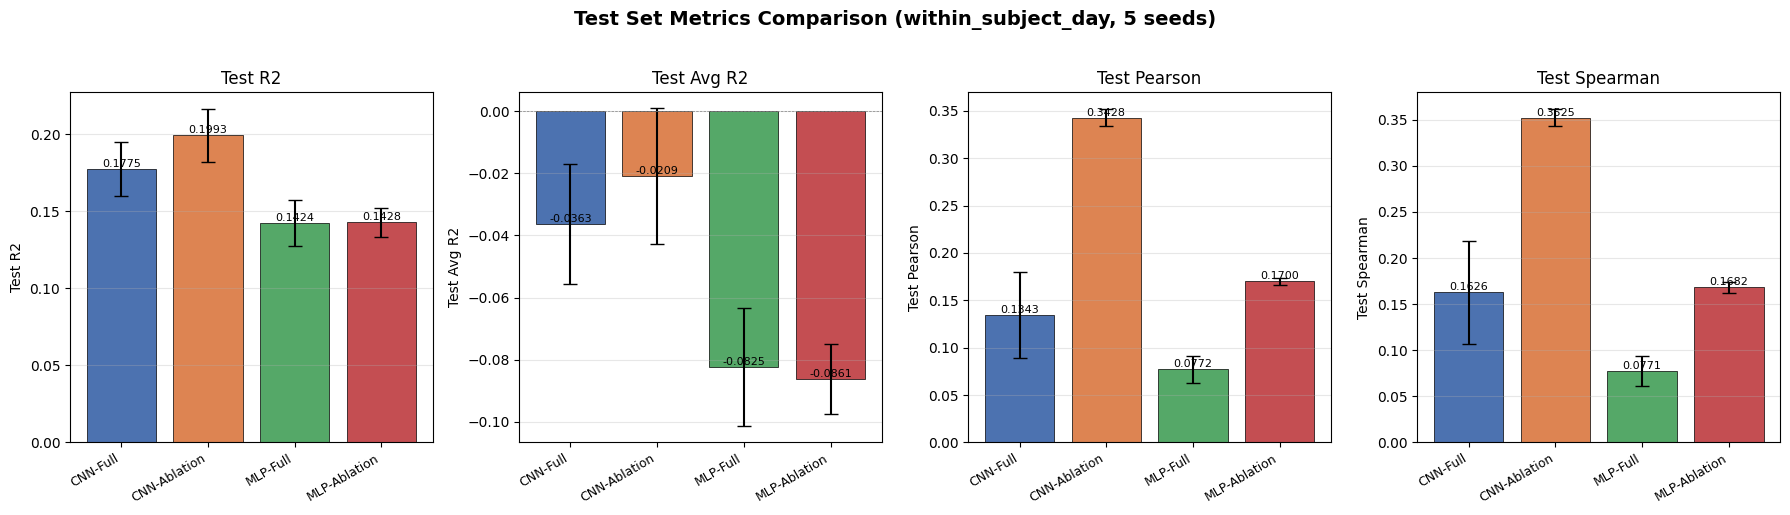

Saved: /root/zjm/cadt_test_code/ablation_comparison_bar.png


In [6]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'

exp_names = list(EXPERIMENTS.keys())
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

# 收集 Test 指标的 mean 和 std
plot_metrics = ['Test R2', 'Test Avg R2 (per-dim)', 'Test Pearson', 'Test Spearman']
plot_labels = ['Test R2', 'Test Avg R2', 'Test Pearson', 'Test Spearman']

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, metric_key, label in zip(axes, plot_metrics, plot_labels):
    means, stds = [], []
    for exp_name in exp_names:
        vals = agg_values(all_data, exp_name, metric_key)
        means.append(np.mean(vals))
        stds.append(np.std(vals, ddof=1))

    bars = ax.bar(range(len(exp_names)), means, yerr=stds, capsize=5,
                  color=colors, edgecolor='black', linewidth=0.5)
    ax.set_xticks(range(len(exp_names)))
    ax.set_xticklabels(exp_names, rotation=30, ha='right', fontsize=9)
    ax.set_ylabel(label)
    ax.set_title(label, fontsize=12)
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
    ax.grid(axis='y', alpha=0.3)

    # 在柱子上标注数值
    for bar, m in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                f'{m:.4f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('Test Set Metrics Comparison (within_subject_day, 5 seeds)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
# [disabled: not referenced by md] plt.savefig('/root/zjm/cadt_test_code/ablation_comparison_bar.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: /root/zjm/cadt_test_code/ablation_comparison_bar.png')

## 4. Per-Emotion Pearson 雷达图

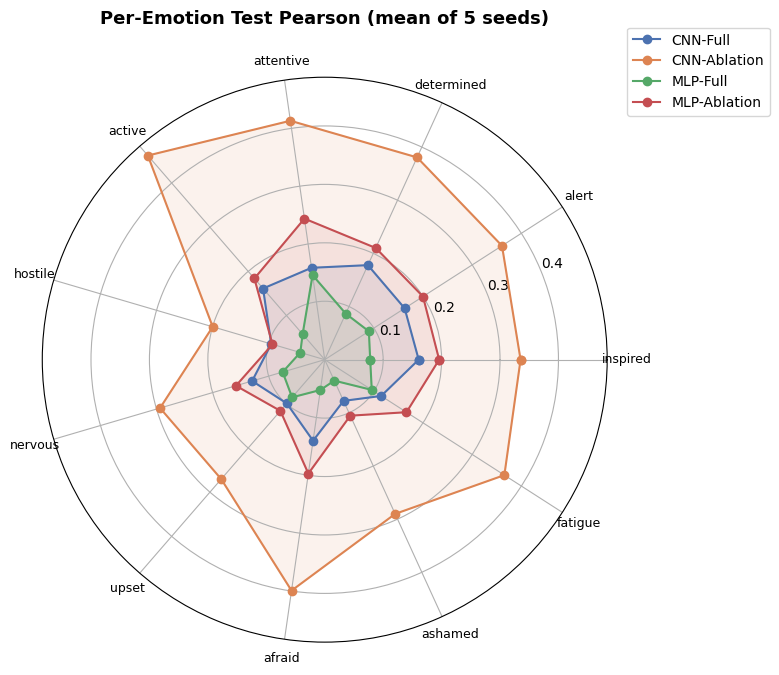

Saved: /root/zjm/cadt_test_code/ablation_radar_pearson.png


In [7]:
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

angles = np.linspace(0, 2 * np.pi, len(EMOTIONS), endpoint=False).tolist()
angles += angles[:1]  # 闭合

for exp_name, color in zip(exp_names, colors):
    means = []
    for emo in EMOTIONS:
        vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric='Pearson')
        means.append(np.mean(vals))
    means += means[:1]
    ax.plot(angles, means, 'o-', linewidth=1.5, label=exp_name, color=color)
    ax.fill(angles, means, alpha=0.1, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(EMOTIONS, fontsize=9)
ax.set_title('Per-Emotion Test Pearson (mean of 5 seeds)', fontsize=13, fontweight='bold', y=1.08)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
ax.grid(True)
plt.tight_layout()
# [disabled: not referenced by md] plt.savefig('/root/zjm/cadt_test_code/ablation_radar_pearson.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: /root/zjm/cadt_test_code/ablation_radar_pearson.png')

## 4b. Per-Emotion \u5206\u7ec4\u67f1\u72b6\u56fe (Pearson / Spearman / R2)\n
\u6bcf\u4e2a\u60c5\u7eea\u5c55\u793a 4 \u7ec4\u5b9e\u9a8c\u7684 mean\u00b1sd\uff085 seeds\uff09

In [8]:
split_mode = 'within_subject_day'
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'
import numpy as np

exp_names = list(EXPERIMENTS.keys())
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

per_emo_metrics = [('Pearson', 'Test Pearson'), ('Spearman', 'Test Spearman'), ('R2', 'Test R2')]

for metric_name, _ in per_emo_metrics:
    fig, ax = plt.subplots(figsize=(16, 6))
    n_emotions = len(EMOTIONS)
    n_exp = len(exp_names)
    bar_width = 0.8 / n_exp
    x = np.arange(n_emotions)

    for i, exp_name in enumerate(exp_names):
        means, stds = [], []
        for emo in EMOTIONS:
            vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric=metric_name)
            means.append(np.mean(vals))
            stds.append(np.std(vals, ddof=1))
        offset = (i - n_exp / 2 + 0.5) * bar_width
        bars = ax.bar(x + offset, means, bar_width, yerr=stds, capsize=3,
                      label=exp_name, color=colors[i], edgecolor='black', linewidth=0.5)

    ax.set_xticks(x)
    ax.set_xticklabels(EMOTIONS, rotation=45, ha='right', fontsize=10)
    ax.set_ylabel(metric_name)
    ax.set_title(f'Per-Emotion Test {metric_name} \u2014 {split_mode} (mean\u00b1sd, 5 seeds)',
                 fontsize=14, fontweight='bold')
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    # [disabled: not referenced by md] plt.savefig(f'/root/zjm/cadt_test_code/per_emotion_{metric_name.lower()}_{split_mode}.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: per_emotion_{metric_name.lower()}_{split_mode}.png')


IndentationError: unexpected indent (121090070.py, line 39)

## 5. 导出 CSV

In [ ]:
output_dir = '/root/zjm/cadt_test_code'

# [disabled: not referenced by md] df_overall.to_csv(os.path.join(output_dir, 'compare_ablation_overall.csv'), index=False)
print(f'Saved: {output_dir}/compare_ablation_overall.csv')

for metric in PER_EMOTION_METRICS:
    rows = []
    for emo in EMOTIONS + ['Average']:
        row = {'Emotion': emo}
        for exp_name in EXPERIMENTS:
            if emo == 'Average':
                vals = agg_values(all_data, exp_name, overall_key_map[metric])
            else:
                vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric=metric)
            row[exp_name] = fmt_ms(vals)
        rows.append(row)
    # [disabled: not referenced by md] pd.DataFrame(rows).to_csv(os.path.join(output_dir, f'compare_ablation_test_{metric}.csv'), index=False)
    print(f'Saved: {output_dir}/compare_ablation_test_{metric}.csv')

print('Done!')